# 6. Allyl Cation: &pi; Orbitals

Simplified **Hückel Molecular Orbital Theory** (SHMO) allows us to create &pi;-molecular orbitals for planar systems. It is **qualitatively** accurate and often all one needs to interpret &pi;-systems in physical organic chemistry. We have explored SHMO and created **MO diagrams** for ethylene, allyl anion & cation, butadiene and the cumyl cation. We have modeled the phenol and the nitrobenzene system as well. And we explored the surprising polar nature of azulene compared to naphthalene. We did all this with *Python* and the *NumPy* \& *SciPy* packages.

Can we do the same, only better, with *GAMESS*? Let’s get busy.

## Learning Goals

In this exercise, we will accomplish the following…

1.	Use *MacMolPlt* to **build** molecules, generate input files and interpret results, and use *Python* to submit jobs to *GAMESS*.
2.	Use *MacMolPlt* to generate graphical **images** of the molecule and surfaces that represent electron density and molecular and local orbitals.
3.	Use the colour-coded **electrostatic potential energy surface** to interpret the polarity of the molecules.
4.	Use the information in the result files to determine the **charge** on each atom and group and compare these to SHMO results.
5.	Create a detailed **MO diagram** for the molecules described above and include relevant **images** of the molecular orbitals.

### Settings

Run this cell first. It loads the book's helper module, `gamess_tools.py`, which finds *GAMESS* using the location you set in `gamess_settings.py` on the [setup page](1_Setup.ipynb). The `.log` files are written into the `runs/` folder next to this notebook. That is the folder to look in when you open a result in *MacMolPlt*.

In [1]:
# ===== SETTINGS =========================================================
# Your GAMESS location is set ONCE, in gamess_settings.py (next to this
# notebook). Edit that file, save it, and restart the kernel.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import gamess_tools as gt

INPUTS = Path("inputs")     # input files that come with the book
RUNS = Path("runs")         # where log files and new input files are written
RUNS.mkdir(exist_ok=True)

HARTREE_TO_KJMOL = 2625.5   # 1 hartree = 2625.5 kJ/mol
# ========================================================================

## The Allyl System

For an example we will build the **allyl cation** and examine the results of the calculation. First we will **build** the allyl group with *MacMolPlt* and attempt to use symmetry. If that fails, we will construct the molecule manually.

In *MacMolPlt* first we will **set the point group** using `Molecule` &rarr; `Set Point Group` &rarr; `Point Group` &rarr; `Cnv` and then `…` &rarr; `Order of Principal Axis` &rarr; `2`. Set up the **build** with `Builder` &rarr; `Edit with Symmetry` and then call the build window with `Builder` &rarr; `Show Build Tools`. It helps to show the axes of the symmetry space via `View` &rarr; `Show Axis`. After that, it is up to **trial and error**.

You will find that each atom placed may be **copied in space** according to the point group. The *z*-axis is the principal axis. Give it a try. I managed to get a structure that resembles an allyl group. See {numref}`fig6A1` for an example.

```{figure} images/pi_symmetryBuild.png
---
width: 500
name: fig6A1
---
Building an allyl cation with symmetry using *MacMolPlt*. The solid atoms are the ones that I placed and the faded ones are being generated according to the requirements of the point group.
```

I then exported an **input file** using `Subwindow` &rarr; `Input Builder`. Be sure to make sure that the multiplicity is 1 (singlet) and the charge is 1 (cation). Use the 6-311G basis set and add *d* and *p* orbitals and use both diffuse functions. The diffuse functions are important as they improve results for **charged** systems. Here is the input file that was generated. Only the *unique atoms* are in the `$DATA` group: the terminal carbon, the central carbon and three hydrogens. The other terminal CH<sub>2</sub> group is generated by symmetry.

```{literalinclude} inputs/AllylCat_6311_U.inp
:label: allylcat_6311_u-inp
:caption: inputs/AllylCat_6311_U.inp
:linenos: True
```

## Running the Optimization

In the original version of this book the file was **submitted** to *GAMESS* via *GamessQ*. Here we run it from *Python* with `gt.run_gamess()`. The optimization takes about 15 seconds.

In [2]:
opt_log = gt.run_gamess(INPUTS / "AllylCat_6311_U.inp")
print(f"Final HF/6-311G(d,p)++ energy: {gt.final_energy(opt_log):.10f} hartree")

AllylCat_6311_U: finished normally (AllylCat_6311_U.log)
Final HF/6-311G(d,p)++ energy: -116.2216480772 hartree


### The Structure

The resulting .log file can be opened with *MacMolPlt*, and bond distances and angles **measured** as shown in {numref}`fig6B`. We can also measure them with *Python* from the final geometry. *GAMESS* lists all eight atoms: the two terminal carbons are atoms 1 and 2, the central carbon is atom 3 and the hydrogens are atoms 4 to 8.

In [3]:
geom = gt.final_geometry(opt_log)
for n, (name, charge, x, y, z) in enumerate(geom, start=1):
    print(f"{n:2d} {name:2s} {x:10.5f} {y:10.5f} {z:10.5f}")

print(f"\nC1–C3 bond length: {gt.distance(geom, 1, 3):.3f} Å")
print(f"C1–C3–C2 angle:    {gt.angle(geom, 1, 3, 2):.1f}°")

 1 C    -0.00000   -1.17688    0.04726
 2 C    -0.00000    1.17688    0.04726
 3 C    -0.00000    0.00000    0.75358
 4 H     0.00000    0.00000    1.82755
 5 H    -0.00000   -2.13290    0.54452
 6 H    -0.00000    2.13290    0.54452
 7 H    -0.00000   -1.18610   -1.03042
 8 H    -0.00000    1.18610   -1.03042

C1–C3 bond length: 1.373 Å
C1–C3–C2 angle:    118.1°


The structure is not a close match to the literature values. For example, the C–C–C bond angle is 118&deg; while the literature value is 124.6&deg;. It is **expected** that the angle should be greater than 120&deg; so I was suspicious of the result. Ions are **tough**. More expensive methods will be needed but we can still obtain fairly decent descriptions of the orbitals and charge density. They won’t be perfect, but will give us the general idea.

```{figure} images/pi_allylresult.png
---
width: 450
name: fig6B
---
HF/6-311G(d,p)++ optimized structure of the allyl cation.
```

## The Energy Calculation

To get accurate energies for the **molecular orbitals**, I used a more advanced method. The *density functional theory* (DFT) method is another way of calculating wavefunctions. Like Hartree-Fock, it uses basis sets but rather than using Gaussian approximations of Slater-type atomic orbitals, it uses “functionals”. That’s all I know. There are many DFT methods. I used the B3LYP method, which I am told is good for **ionic** species. The orbitals discussed below are from a B3LYP/6-311G(d,p)++ energy calculation of the HF/6-311G(d,p)++ optimized structure.

Below is the **input file** for the energy calculation. Line 3 asks for localized orbitals (`LOCAL=RUEDNBRG`) so that *MacMolPlt* can draw the local bonding orbitals.

```{literalinclude} inputs/AllylCat_B3LYP_U_E.inp
:label: allylcat_b3lyp_u_e-inp
:caption: inputs/AllylCat_B3LYP_U_E.inp
:linenos: True
:emphasize-lines: 2, 3
```

The coordinates in this file are the ones from my own optimization. Rather than copy and paste coordinates by hand, `gt.new_input()` writes a copy of this file with the symmetry-unique atoms from **your** optimization in place of mine.

In [4]:
energy_inp = gt.new_input(INPUTS / "AllylCat_B3LYP_U_E.inp", RUNS / "AllylCat_B3LYP_U_E.inp",
                          atoms=gt.final_geometry(opt_log, unique=True))
energy_log = gt.run_gamess(energy_inp)
print(f"Final B3LYP/6-311G(d,p)++ energy: {gt.final_energy(energy_log):.10f} hartree")

AllylCat_B3LYP_U_E: finished normally (AllylCat_B3LYP_U_E.log)
Final B3LYP/6-311G(d,p)++ energy: -116.9219769872 hartree


## Analysis of Charges

Open `runs/AllylCat_B3LYP_U_E.log` in *MacMolPlt*. By using `Subwindow` &rarr; `Surfaces` &rarr; `3D Electron Density` and choosing to colour by `MEP` (molecular electrostatic potential) we can obtain an **image** that represents the electron density of the molecule and the colours mapped onto the surface represent the **charge**. Red are regions that repel a positive charge and blue are regions that attract a positive charge. Green is neutral. We can see in {numref}`fig6C` that the positive charge is **located** on the two terminal carbon groups, as expected.

```{margin}
Someday, I will explore using *Multiwfn*, a package for analyzing molecular wavefunction data produced by programs like *GAMESS*. Perhaps you will be the pioneer. See more [here](http://sobereva.com/multiwfn/index.html).
```

```{figure} images/pi_1.png
---
width: 450
name: fig6C
---
Electron density surface coloured by electrostatic potential. *MacMolPlt* does not give the best color contrast, but it does the job.
```

We can get an **approximation** of the charge held by each group from the data in the result .log file. In the original book we opened the file in a text editor and **searched** for the last occurrence of the word “`LOWDIN`”. `gt.excerpt()` does the same search and prints the lines that follow.

In [5]:
gt.excerpt(energy_log, "TOTAL MULLIKEN AND LOWDIN ATOMIC POPULATIONS", after=9)

 3150            TOTAL MULLIKEN AND LOWDIN ATOMIC POPULATIONS
 3151         ATOM         MULL.POP.    CHARGE          LOW.POP.     CHARGE
 3152      1 C             6.231114   -0.231114         5.815258    0.184742
 3153      2 C             6.231114   -0.231114         5.815258    0.184742
 3154      3 C             5.723100    0.276900         6.070767   -0.070767
 3155      4 H             0.730396    0.269604         0.862629    0.137371
 3156      5 H             0.764983    0.235017         0.855016    0.144984
 3157      6 H             0.764983    0.235017         0.855016    0.144984
 3158      7 H             0.777154    0.222846         0.863028    0.136972
 3159      8 H             0.777154    0.222846         0.863028    0.136972


Here are reported **calculations** of electron population and partial atomic charge according to two common methods: Mulliken and Löwdin. We will use Löwdin. We see that the two terminal carbons (C1 & C2) are positively charged. However it is better to calculate the **total charge** on the carbon groups (carbons and hydrogens) and *GAMESS* is having the positively charged carbon atoms pull in electrons from the hydrogen atoms to spread the charge out.

`gt.atomic_charges()` reads that table. To add up the groups, *Python* attaches each hydrogen to its nearest carbon (the atom numbers can also be shown in *MacMolPlt*).

In [6]:
charges = gt.atomic_charges(energy_log)
carbons = [n for n, atom in enumerate(geom, start=1) if atom[0] == "C"]
hydrogens = [n for n, atom in enumerate(geom, start=1) if atom[0] == "H"]

groups = {c: [c] for c in carbons}
for h in hydrogens:
    nearest = min(carbons, key=lambda c: gt.distance(geom, c, h))
    groups[nearest].append(h)

print(f"{'Group':<14}{'Lowdin charge':>14}")
total = 0.0
for c, members in groups.items():
    q = sum(charges[n - 1][2] for n in members)
    total += q
    name = "+".join(f"{geom[n - 1][0]}{n}" for n in members)
    print(f"{name:<14}{q:+14.3f}")
print(f"{'Total':<14}{total:+14.3f}")

Group          Lowdin charge
C1+H5+H7              +0.467
C2+H6+H8              +0.467
C3+H4                 +0.067
Total                 +1.000


We see that the ends of the allyl cation **share** the charge 50/50. This is consistent with the SHMO analysis, which would have placed the full charge of the group on the carbon atom alone (SHMO ignores the hydrogen atoms).

```{note}
The same part of the log file has a `BOND ORDER AND VALENCE ANALYSIS` with a column called `FREE VALENCE`. That is not the Hückel free valence: for a closed-shell molecule such as the allyl cation it is always zero. Compare the charges, not that column, with your SHMO results.
```

## Analysis of Molecular Orbitals

The molecular orbital **diagram** can be created using data from the *GAMESS* result file as interpreted by *MacMolPlt*. We can provide images of the **local** bonding &sigma;-orbitals and the &pi;-orbitals to create a basic interpretation of the bonding and reactivity of the allyl cation. We can also use the calculated bonding MOs and their **relative energies** (the eigenvalues for each MO).

Use `Subwindow` &rarr; `Surfaces` &rarr; `3D Molecular Orbitals` and explore the options to create **images** as seen in {numref}`fig6D`. The energies for each molecular **eigenvector** (molecular orbital) are listed in the window. You can also find them in the result file under the heading `EIGENVECTORS`, where each MO is a column of values (the eigenvector) with an energy value at the top (the eigenvalue). `gt.molecular_orbitals()` reads that table.

The first three MOs will be the 1*s* core orbitals of carbon. There will be 17 MOs that are created by the valence AOs (*s*, *p<sub>x</sub>*, *p<sub>y</sub>*, *p<sub>z</sub>* for each carbon and *s* for each hydrogen). The first eight valence MOs will be **filled** (that means the first 11 are filled counting the core orbitals). Rather than use just 17 valence shell AOs, *GAMESS* used many more basis functions. It’s just being thorough and these higher level empty MOs do have slight effects on the energy and structure and are there to provide greater accuracy.

In [7]:
mo = gt.molecular_orbitals(energy_log)
homo = gt.occupied_orbitals(energy_log)
print(f"{len(mo['labels'])} basis functions, {homo} occupied orbitals")

# the molecule lies in the yz-plane, so the pi orbitals are made of X functions
pi_share = gt.p_character(mo, "X")

for n in range(homo + 4):
    kind = "pi" if pi_share[n] > 0.5 else "sigma"
    tag = "HOMO" if n + 1 == homo else ("LUMO" if n + 1 == homo + 1 else "")
    print(f"MO {n + 1:2d}  {mo['energies'][n]:9.4f} hartree  {mo['symmetries'][n]:3s} {kind:6s} {tag}")

104 basis functions, 11 occupied orbitals
MO  1   -10.4857 hartree  A1  sigma  
MO  2   -10.4856 hartree  B2  sigma  
MO  3   -10.4403 hartree  A1  sigma  
MO  4    -1.0784 hartree  A1  sigma  
MO  5    -0.9461 hartree  B2  sigma  
MO  6    -0.8221 hartree  A1  sigma  
MO  7    -0.7506 hartree  A1  sigma  
MO  8    -0.7106 hartree  B2  sigma  
MO  9    -0.6468 hartree  B2  sigma  
MO 10    -0.6300 hartree  A1  sigma  
MO 11    -0.5785 hartree  B1  pi     HOMO
MO 12    -0.3841 hartree  A2  pi     LUMO
MO 13    -0.2147 hartree  B1  pi     
MO 14    -0.1596 hartree  A1  sigma  
MO 15    -0.1430 hartree  A1  sigma  


`gt.p_character()` adds up the squares of the coefficients that belong to *p<sub>x</sub>* functions. The molecule lies in the *yz*-plane, so an orbital built almost entirely from *p<sub>x</sub>* functions is a &pi;-orbital. *Python* finds three of them. The allyl cation has only two &pi;-electrons, so only the bonding &pi;-orbital (MO 11, the HOMO) is filled. The non-bonding &pi;-orbital (MO 12) is the LUMO and the antibonding &pi;-orbital is MO 13.

Can you make a **diagram** like the one in {numref}`fig6D`? I exported images from *MacMolPlt* and made the diagram using the graphics program [*Affinity Designer*](https://affinity.serif.com), but you could use the free [*Inkscape*](https://inkscape.org) program as well.

```{figure} images/pi_MO-Diagram_lowres.png
---
width: 500
name: fig6D
---
MO diagrams for the allyl cation. Whether we imagine the system using combinations of hybrid atomic orbitals to create local MOs or use the true AOs to calculate the global MOs we see that the LUMO is the same with both approaches and that is what counts.
```

*Python* can draw the energy levels for the skeleton of such a diagram. The &pi;-orbitals are drawn in orange and the &sigma;-orbitals in blue. Filled orbitals carry a pair of electrons.

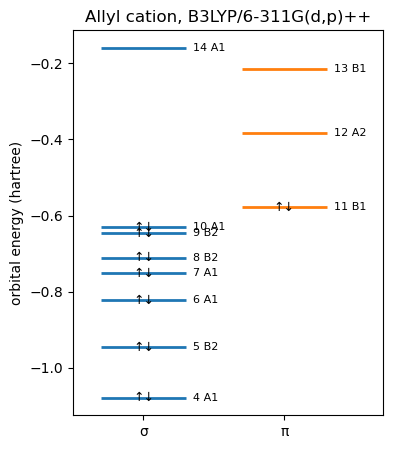

In [8]:
fig, ax = plt.subplots(figsize=(4, 5))
for n in range(3, homo + 3):                      # skip the three C 1s core orbitals
    e = mo["energies"][n]
    color = "tab:orange" if pi_share[n] > 0.5 else "tab:blue"
    x = 1.0 if pi_share[n] > 0.5 else 0.0
    ax.hlines(e, x, x + 0.6, color=color, lw=2)
    ax.text(x + 0.65, e, f"{n + 1} {mo['symmetries'][n]}", va="center", fontsize=8)
    if n < homo:
        ax.text(x + 0.3, e, "↑↓", ha="center", va="center", fontsize=9)
ax.set_xticks([0.3, 1.3], ["σ", "π"])
ax.set_xlim(-0.2, 2.0)
ax.set_ylabel("orbital energy (hartree)")
ax.set_title("Allyl cation, B3LYP/6-311G(d,p)++")
plt.show()

## Comparing AO Coefficients

In SHMO theory we get the **coefficients** of each *p*-atomic orbital as they contribute to each &pi;-molecular orbital. These coefficients make the list of numbers that make up the eigenvectors for each HMO. There are similar coefficients in the molecular eigenvectors in the **result file**. Here is the start of the block that holds orbitals 11 to 15 in the last `EIGENVECTORS` table.

In [9]:
gt.excerpt(energy_log, f"{homo:>5d}{homo + 1:>11d}", before=0, after=10)

  899                       11         12         13         14         15
  900                     -0.5785    -0.3841    -0.2147    -0.1596    -0.1430
  901                       B1         A2         B1         A1         A1  
  902      1  C  1  S   -0.000000   0.000000   0.000000  -0.030566  -0.005520
  903      2  C  1  S   -0.000000   0.000000   0.000000  -0.050191  -0.009263
  904      3  C  1  X    0.133702   0.200077  -0.133119  -0.000000  -0.000000
  905      4  C  1  Y   -0.000000   0.000000   0.000000  -0.037357   0.025185
  906      5  C  1  Z   -0.000000   0.000000   0.000000  -0.035064  -0.074438
  907      6  C  1  S   -0.000000   0.000000   0.000000   0.171075   0.022781
  908      7  C  1  X    0.211648   0.312784  -0.197759  -0.000000  -0.000000
  909      8  C  1  Y   -0.000000   0.000000   0.000000  -0.056081   0.042781


We see that the *p<sub>x</sub>* orbitals are the *p*-atomic orbitals that contribute to the &pi;-MOs. (The molecule is in the *yz*-plane.) The terminal carbons are C1 and C2 and the central carbon is C3. Each carbon has several *p<sub>x</sub>* functions in this basis set (an inner one and outer ones). Below, *Python* picks the first (inner valence) *p<sub>x</sub>* function on each carbon, as I did by eye in the original version of this page, and prints its coefficient in each &pi;-MO.

In [10]:
pi_mos = [n for n in range(homo + 2) if pi_share[n] > 0.5]      # the three pi MOs
rows = [mo["labels"].index(f"C {c} X") for c in (1, 3, 2)]     # first C px on C1, C3, C2

print(f"{'Orbital':<9}{'C1 px':>9}{'C3 px':>9}{'C2 px':>9}")
for n in pi_mos:
    c1, c3, c2 = mo["coefficients"][rows, n]
    print(f"{n + 1:<9}{c1:9.3f}{c3:9.3f}{c2:9.3f}")

Orbital      C1 px    C3 px    C2 px
11           0.134    0.180    0.134
12           0.200    0.000   -0.200
13          -0.133    0.218   -0.133


How do these coefficients **compare** to the HMO method? They are **smaller** in magnitude because these *p*-orbitals are used in many of the other orbitals that were **included** in the *GAMESS* calculation while SHMO only considers the three &pi;-MOs.

We can make the comparison fairer by **rescaling** each set of three coefficients so that their squares add up to 1, as they do in SHMO. The cell below does that and also solves the Hückel problem for allyl with *NumPy*, exactly as in the SHMO exercises. (The overall sign of an orbital means nothing, so compare the patterns of signs, not the signs themselves.)

In [11]:
# Hückel matrix for allyl in units of beta, atoms in the order C1, C3, C2
H = np.array([[0, 1, 0],
              [1, 0, 1],
              [0, 1, 0]])
x, c_huckel = np.linalg.eigh(H)
order = np.argsort(-x)                 # energy = alpha + x*beta, beta < 0: largest x is lowest

print(f"{'':<16}{'C1':>8}{'C3':>8}{'C2':>8}")
for k, n in enumerate(pi_mos):
    c = mo["coefficients"][rows, n]
    print(f"GAMESS MO {n + 1:<6}" + "".join(f"{v:8.3f}" for v in c / np.linalg.norm(c)))
    label = f"Hückel α{round(x[order[k]], 2) + 0.0:+.2f}β"
    print(f"{label:<16}" + "".join(f"{v:8.3f}" for v in c_huckel[:, order[k]]))

                      C1      C3      C2
GAMESS MO 11       0.512   0.689   0.512
Hückel α+1.41β     0.500   0.707   0.500
GAMESS MO 12       0.707   0.000  -0.707
Hückel α+0.00β     0.707  -0.000  -0.707
GAMESS MO 13      -0.462   0.757  -0.462
Hückel α-1.41β    -0.500   0.707  -0.500


After rescaling, the *GAMESS* coefficients are close to the Hückel values of $\tfrac{1}{2}$, $\tfrac{1}{\sqrt{2}}$ and 0: the bonding orbital is spread over all three atoms with the largest share on the central carbon, the non-bonding orbital (the LUMO of the cation) has a node at the central carbon, and the antibonding orbital alternates in sign. The simple theory gets the shapes right.

## Summary

We have created input files and produced output files for a **charged molecule**. We have optimized the **structure** at HF/6-311G(d,p)++ and calculated the **energy** at B3LYP/6-311G(d,p)++. We then **visualized** the electron density and colored the **surface** with the values of the **electrostatic potential**. This revealed that the ends of the cation shared the positive charge. We read the charges from the result file with *Python* and calculated the **partial charges** on the carbon groups and again observed equal charge sharing at the ends.

We then visualized the **local bonding MOs** for representative C–H and C–C bonds. We also **visualized** the three &pi;-MOs and the seven &sigma;-MOs and created molecular orbital diagrams using the simple combination of hybrid AOs and also with the complete combination of all AOs. We also determined the **coefficients** for the *p*-AOs that contributed from each carbon atom toward the &pi;-system and compared them with SHMO.

## Exercise

Read the accompanying discussion and then **try** the following exercises.

### The Activity

Construct **ethylene** and then optimize the structure at HF/6-311G(d,p)++. Perform an **energy** calculation at B3LYP/6-311G(d,p)++ with instructions to write data for **localized MOs**. Use symmetry in the construction of the input file. The code cells above will work for your molecule with small changes: the input file names, the axis that is perpendicular to your molecule in `gt.p_character()`, and the carbon atom numbers.

### The Report

Present a ONE PAGE document with the molecular orbital diagram with **images** of the bonding orbitals. Present a table of charges for each carbon group (a carbon atom and all attached hydrogens). Present a table of *p*-orbital **coefficients** for each &pi;-MO. Include an image of the electron density mapped with the electrostatic potential to demonstrate charge location (admittedly there will be no charges in ethylene, but other molecules will reveal detail here).

**Compare** the &pi;-MOs, coefficients and **charges** from your *GAMESS* calculations to the values from the exercise with SHMO &pi;-systems.

Now **repeat** the exercise for the following situations as assigned. Don’t bother making any more images of &sigma;-orbitals. Just show &pi;-orbitals in your **diagrams** (but please do indicate the &sigma;-orbitals with lines for relative energy levels and arrows for electrons).

1.	Allyl anion
2.	Butadiene
3.	Pentadienyl cation or anion
4.	Cumyl cation
5.	Naphthalene
6.	Azulene

## AI Statement

This page was converted from the original Markdown page `6_Pi_Orbitals.md` to a *Jupyter* notebook with the help of Claude (Anthropic), following the author's instructions.

- **Original text kept (about 75 %).** The introduction, learning goals, the *MacMolPlt* symmetry-building and surface instructions, the discussion of the structure, charges, MOs and coefficients, the summary, the exercise and all figures are the author's. The two input files are the author's. Small edits: typos fixed (e.g. “6-3111”), figure captions tidied, and the free-valence learning goal was dropped because *GAMESS* does not report a Hückel free valence (a note explains why).
- **Written by AI.** The settings cell, all code cells and the sentences that introduce them; the group-charge sum done by *Python*; the π/σ sorting of the MOs with `gt.p_character()`; the energy-level plot; the rescaled-coefficient comparison with a *NumPy* Hückel calculation; and the helpers `p_character` and `atomic_charges` in `gamess_tools.py`.
- **Changed workflow.** Jobs are run with `run_gamess()` instead of *GamessQ*, the B3LYP input is written from your own optimized geometry with `new_input()`, and the charge table and eigenvector excerpts are read by *Python* instead of searching the log file in a text editor. The numbers in the text come from the original runs; the printed tables come from the runs made by this notebook, so they may differ slightly. *MacMolPlt* is still used to build the molecule and to draw the surfaces and orbitals.